# Slutlig modellutvärdering – Scania APS

I den här notebooken utvärderar vi Logistic Regression och Random Forest på Scanias officiella testdata. Syftet är att undersöka hur väl modellerna identifierar APS-relaterade fel och jämföra deras resultat utifrån projektets kostnadsmodell.

Modellerna tränas på den officiella träningsdatan med tidigare valda inställningar och tröskelvärden. Testdatan används endast för den slutliga utvärderingen.

Vi jämför även med en enkel Dummy-baseline för att visa varför accuracy inte är ett tillräckligt mått när klasserna är så ojämnt fördelade.

In [1]:

from pathlib import Path
import sys

# Hitta projektets huvudmapp
PROJECT_ROOT = Path.cwd().resolve()

if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "src").is_dir():
    raise FileNotFoundError("Projektmappen kunde inte hittas.")

sys.path.insert(0, str(PROJECT_ROOT))

print("Projektmappen hittades:", PROJECT_ROOT)


Projektmappen hittades: C:\Users\EliesaDudus\OneDrive - Diagonal Bio\Desktop\Gruppuppgift\scania-aps-predictive-maintenance-main


In [2]:

from src.data.load_data import load_test_data

# Läs in den officiella testdatan
test_data = load_test_data()

# Visa hur stor datan är
print("Antal observationer:", test_data.shape[0])
print("Antal kolumner:", test_data.shape[1])


Antal observationer: 16000
Antal kolumner: 171


In [3]:

from src.data.preprocess import split_features_target, encode_binary_target

# Dela upp testdatan i variabler och facit
X_test, y_test_text = split_features_target(test_data)

# Omvandla neg/pos till 0/1
y_test = encode_binary_target(y_test_text)

print("Antal testobservationer:", len(X_test))
print("Antal verkliga APS-fel:", int(y_test.sum()))
print("Antal utan APS-fel:", int((y_test == 0).sum()))


Antal testobservationer: 16000
Antal verkliga APS-fel: 375
Antal utan APS-fel: 15625


In [4]:

from src.data.load_data import load_training_data

# Läs in gruppens officiella träningsdata
training_data = load_training_data()

# Dela upp variabler och facit
X_train, y_train_text = split_features_target(training_data)
y_train = encode_binary_target(y_train_text)

# Kontrollera att träning och test har samma variabler
assert list(X_train.columns) == list(X_test.columns)

print("Träningsdata:", X_train.shape)
print("Testdata:", X_test.shape)
print("Antal APS-fel i träningsdatan:", int(y_train.sum()))
print("Variablerna matchar!")


Träningsdata: (60000, 170)
Testdata: (16000, 170)
Antal APS-fel i träningsdatan: 1000
Variablerna matchar!


In [5]:

from src.models.baseline import build_logistic_regression_pipeline

# Skapa gruppens Logistic Regression-modell
lr_model = build_logistic_regression_pipeline(random_state=42)

# Träna modellen på träningsdatan
lr_model.fit(X_train, y_train)

print("Logistic Regression är färdigtränad!")


Logistic Regression är färdigtränad!


In [6]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from src.models.baseline import (
    CONSTANT_FEATURE_TO_DROP,
    DropColumnsTransformer,
)

# Återskapa Tims valda Random Forest
rf_model = Pipeline(steps=[
    ("drop_constant", DropColumnsTransformer(
        columns=[CONSTANT_FEATURE_TO_DROP]
    )),
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("classifier", RandomForestClassifier(
        n_estimators=110,
        max_depth=20,
        min_samples_leaf=2,
        class_weight={0: 1, 1: 15},
        max_features="sqrt",
        max_samples=0.8,
        n_jobs=2,
        random_state=42
    ))
])

# Träna endast på träningsdatan
rf_model.fit(X_train, y_train)

print("Random Forest är färdigtränad!")


Random Forest är färdigtränad!


In [7]:

# Fastställda tröskelvärden från Tims modellutveckling
LR_THRESHOLD = 0.460
RF_THRESHOLD = 0.105

# Beräkna modellernas sannolikhetspoäng för APS-fel
lr_prob = lr_model.predict_proba(X_test)[:, 1]
rf_prob = rf_model.predict_proba(X_test)[:, 1]

# Omvandla poängen till förutsägelser: 0 eller 1
lr_pred = (lr_prob >= LR_THRESHOLD).astype(int)
rf_pred = (rf_prob >= RF_THRESHOLD).astype(int)

print("Antal APS-varningar från Logistic Regression:", lr_pred.sum())
print("Antal APS-varningar från Random Forest:", rf_pred.sum())


Antal APS-varningar från Logistic Regression: 803
Antal APS-varningar från Random Forest: 695


In [8]:

import pandas as pd
from IPython.display import display
from src.evaluation.metrics import evaluate_binary_classifier

# Utvärdera båda modellerna på officiella testdatan
lr_results = evaluate_binary_classifier(
    y_test, lr_pred, lr_prob
)

rf_results = evaluate_binary_classifier(
    y_test, rf_pred, rf_prob
)

# Sammanställ resultaten i en tabell
results_table = pd.DataFrame({
    "Logistic Regression": lr_results,
    "Random Forest": rf_results
}).T

display(results_table.round(4))


,accuracy,precision,recall,f1,tn,fp,fn,tp,business_cost,pr_auc
Logistic Regression,0.9706,0.4408,0.944,0.6010,15176.0,449.0,21.0,354.0,14990.0,0.8030
Random Forest,0.9781,0.5180,0.960,0.6729,15290.0,335.0,15.0,360.0,10850.0,0.8989


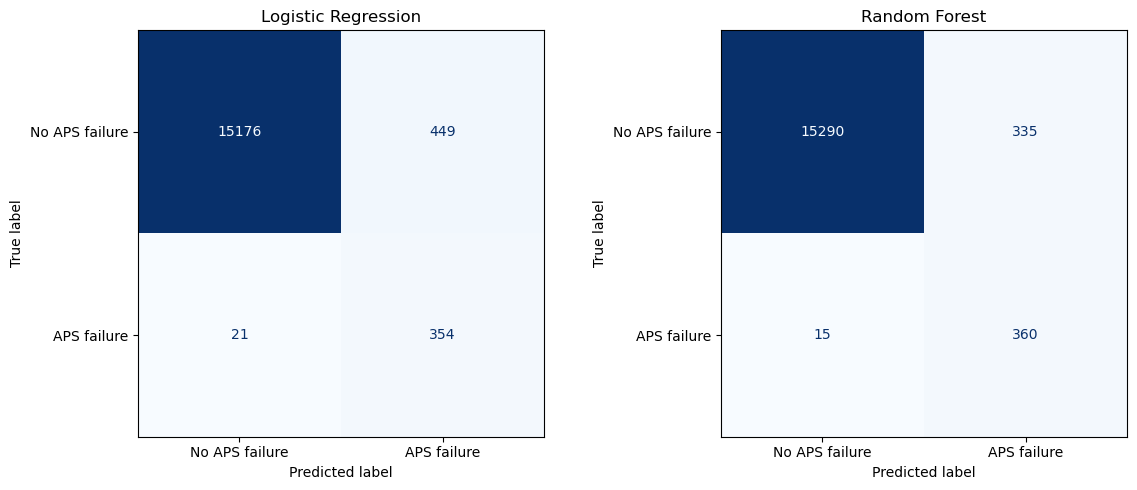

In [9]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, lr_pred,
    display_labels=["No APS failure", "APS failure"],
    cmap="Blues",
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test, rf_pred,
    display_labels=["No APS failure", "APS failure"],
    cmap="Blues",
    ax=axes[1],
    colorbar=False
)
axes[1].set_title("Random Forest")

plt.tight_layout()
plt.show()


## Slutlig modellutvärdering

### Resultat på testdata

Den slutliga utvärderingen genomfördes på Scanias officiella testdata med totalt 16 000 observationer, varav 375 representerade APS-relaterade fel. Båda modellerna tränades på träningsdatan med de inställningar och tröskelvärden som tidigare hade valts under modellutvecklingen.

Resultaten visar att Random Forest presterade bättre än Logistic Regression på samtliga utvärderingsmått.

Random Forest identifierade 360 av de 375 verkliga APS-felen, vilket motsvarar en recall på 96,0 %. Logistic Regression identifierade 354 fel och uppnådde en recall på 94,4 %.

Skillnaden syns även i antalet falsklarm. Random Forest gav 335 falskt positiva förutsägelser, jämfört med 449 för Logistic Regression. Det innebär att Random Forest både missade färre verkliga fel och gav färre felaktiga varningar.

### Kostnadsbaserad jämförelse

Eftersom ett missat APS-fel enligt projektets kostnadsmodell är betydligt dyrare än ett falsklarm används den totala felklassificeringskostnaden som huvudsakligt jämförelsemått.

Kostnaden beräknas enligt:

**Total kostnad = 10 × FP + 500 × FN**

Logistic Regression fick en total kostnad på 14 990, medan Random Forest fick 10 850. Det motsvarar en kostnadsminskning på cirka 27,6 %.

Resultatet visar att Random Forest är det bättre alternativet utifrån projektets kostnadsmodell. Förbättringen beror både på att modellen upptäcker fler APS-fel och att den ger färre falsklarm.

### Begränsningar

Trots de goda resultaten finns det begränsningar. Random Forest missade fortfarande 15 verkliga APS-fel och gav 335 falsklarm. Modellen kan därför inte förväntas fatta underhållsbeslut helt självständigt.

Datasetet innehåller dessutom många saknade värden och anonymiserade variabler. Det gör det svårt att förstå vilka tekniska faktorer som ligger bakom modellens förutsägelser.

Resultaten bygger också på historiska data och en förutbestämd kostnadsmodell. För att kunna bedöma hur väl modellen fungerar i praktiken skulle den behöva testas på nya, representativa fordonsdata och under verkliga underhållsförhållanden.

### Slutsats

Den slutliga utvärderingen visar att Random Forest ger bättre resultat än Logistic Regression på den officiella testdatan. Modellen identifierar fler APS-relaterade fel, genererar färre falsklarm och ger en lägre total felklassificeringskostnad.

Utifrån resultaten är Random Forest det mest lämpliga alternativet av de två undersökta modellerna. Den har potential att användas som beslutsstöd för att prioritera vilka fordon som bör kontrolleras, men ytterligare validering krävs innan den kan

In [10]:

from src.models.baseline import build_dummy_reference_classifier

# Skapa och träna en enkel referensmodell
dummy_model = build_dummy_reference_classifier()
dummy_model.fit(X_train, y_train)

# Gör förutsägelser på testdatan
dummy_pred = dummy_model.predict(X_test)
dummy_prob = dummy_model.predict_proba(X_test)[:, 1]

# Beräkna samma mått som för de andra modellerna
dummy_results = evaluate_binary_classifier(
    y_test, dummy_pred, dummy_prob
)

# Jämför alla tre modeller
final_comparison = pd.DataFrame({
    "Dummy baseline": dummy_results,
    "Logistic Regression": lr_results,
    "Random Forest": rf_results
}).T

display(final_comparison.round(4))


,accuracy,precision,recall,f1,tn,fp,fn,tp,business_cost,pr_auc
Dummy baseline,0.9766,0.0000,0.000,0.0000,15625.0,0.0,375.0,0.0,187500.0,0.0234
Logistic Regression,0.9706,0.4408,0.944,0.6010,15176.0,449.0,21.0,354.0,14990.0,0.8030
Random Forest,0.9781,0.5180,0.960,0.6729,15290.0,335.0,15.0,360.0,10850.0,0.8989


Som jämförelse användes även en Dummy-baseline som alltid förutsäger den vanligaste klassen, alltså att inget APS-fel finns. Modellen fick en accuracy på 97,66 %, men missade samtidigt samtliga 375 verkliga APS-fel. Den totala felkostnaden blev därför 187 500, vilket är betydligt högre än för de två andra modellerna.

Det visar varför accuracy kan vara missvisande när datasetet innehåller väldigt få positiva fall. I det här projektet är det viktigare att hitta verkliga APS-fel och hålla nere kostnaden för felaktiga förutsägelser.